In [23]:
import sympy as sp
import numpy as np
import scipy
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from sympy import  symbols, sin , cos, lambdify, atan, acos, nsolve
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

### Cinematica

In [24]:
t = symbols('t')
theta2, theta3, x, theta1 = dynamicsymbols('theta2, theta3, x, theta1')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = A.orientnew('B', 'Axis', (N.z, -theta2))
C = B.orientnew('C', 'Axis', (N.z, -theta3))

pos = 0.2*A.x + 0.15*B.x + 0.6*C.x - 0.05*N.y - x*N.x
vel = pos.diff(t, N).simplify()
ace = vel.diff(t, N).simplify()

pos_var = [theta1, theta2, theta3, x]
vel_var = [theta1.diff(t), theta2.diff(t), theta3.diff(t), x.diff(t)]
ace_var = [theta1.diff(t,t), theta2.diff(t,t), theta3.diff(t,t), x.diff(t,t)]

pos_fun = lambdify([theta1, theta2, theta3, x], [pos.dot(N.x), pos.dot(N.y)])

[AV, bV] = sp.linear_eq_to_matrix([vel.dot(N.x), vel.dot(N.y)], [theta2.diff(t), theta3.diff(t)])
AV_fun = sp.lambdify(pos_var + vel_var, AV)
bV_fun = sp.lambdify(pos_var + vel_var, bV)

[AA, bA] = sp.linear_eq_to_matrix([ace.dot(N.x), ace.dot(N.y)], [theta2.diff(t,t), theta3.diff(t,t)])
AA_fun = sp.lambdify(pos_var + vel_var + ace_var, AA)
bA_fun = sp.lambdify(pos_var + vel_var + ace_var, bA)

In [29]:
AV

Matrix([
[ 0.15*sin(theta1(t) - theta2(t)) - 0.6*sin(-theta1(t) + theta2(t) + theta3(t)), -0.6*sin(-theta1(t) + theta2(t) + theta3(t))],
[-0.15*cos(theta1(t) - theta2(t)) - 0.6*cos(-theta1(t) + theta2(t) + theta3(t)), -0.6*cos(-theta1(t) + theta2(t) + theta3(t))]])

In [27]:
bV

Matrix([
[0.15*sin(theta1(t) - theta2(t))*Derivative(theta1(t), t) - 0.6*sin(-theta1(t) + theta2(t) + theta3(t))*Derivative(theta1(t), t) + 0.2*sin(theta1(t))*Derivative(theta1(t), t) + 1.0*Derivative(x(t), t)],
[                         -0.15*cos(theta1(t) - theta2(t))*Derivative(theta1(t), t) - 0.6*cos(-theta1(t) + theta2(t) + theta3(t))*Derivative(theta1(t), t) - 0.2*cos(theta1(t))*Derivative(theta1(t), t)]])

In [15]:
omega = 5
fD = ((70 + 5*sin(omega*t))/100)
vD = fD.diff(t)
aD = fD.diff(t,t)

In [16]:
t_ = np.linspace(0, 5, 100)
theta_1 = np.linspace(50, 75, 100)

def posicion(time, theta1):
    fsolve_fun = lambda z: pos_fun(np.deg2rad(50) + 3*time, z[0], z[1], fD.subs({t:time}))
    out = fsolve(fsolve_fun, [0.56, 0.50], full_output = True)
    return [np.deg2rad(50) + 3*time, out[0][0], out[0][1], fD.subs({t:time})]

def cinematica(time, theta1, theta1dot, theta1ddot):
    p = posicion(time, theta1)
    args = [*p, theta1dot, None, None, vD.subs({t:time})]
    pdot = np.concatenate([[theta1dot], np.matmul(np.linalg.pinv(AV_fun(*args)), bV_fun(*args)).flatten(), [vD.subs({t:time})]])
    args2 = [*p, *pdot, theta1ddot, None, None, aD.subs({t:time})]
    pddot = np.concatenate([[theta1ddot], np.matmul(np.linalg.pinv(AA_fun(*args2)), bA_fun(*args2)).flatten(), [aD.subs({t:time})]])
    return [np.deg2rad(50) + 3*time, p[1], p[2], p[3], *pdot, *pddot]

cinematica(t_[1], theta_1[1], 3, 0)

[np.float64(1.0241797775123163),
 np.float64(-0.09295694534411608),
 np.float64(1.557360253117844),
 0.712492495817949,
 3,
 8.43781467578189,
 -5.52181511091399,
 0.242071143893615,
 0,
 -0.183762335059443,
 -9.96863151469883,
 -0.312312395448723]

[np.float64(1.8252064402205777),
 np.float64(1.557360253117844),
 np.float64(1.2631989396985044),
 np.float64(0.9201515763852792),
 np.float64(0.42672143216076625),
 np.float64(-0.001551389293497458),
 np.float64(-0.0034401057611568395),
 np.float64(-0.001294820502469993),
 np.float64(6.282841791205813),
 np.float64(-0.0018650211256248414),
 np.float64(0.0006812615035068571),
 np.float64(6.283251183543967),
 np.float64(6.283988227345492),
 np.float64(12.567020502446836),
 np.float64(6.284044777844315),
 np.float64(25.134148316622),
 np.float64(12.565811959562621),
 np.float64(31.41572205884046),
 np.float64(12.566680288672037),
 np.float64(18.84994624720257),
 np.float64(37.70280246519847),
 np.float64(75.39814280674814),
 np.float64(12.566626444426154),
 np.float64(12.566201611395535),
 np.float64(18.849634927457416),
 np.float64(43.982440602561375),
 np.float64(-5.821943051478897),
 np.float64(24.39817578457335),
 np.float64(26.087733127560707),
 np.float64(20.003975427025708),
 np.f

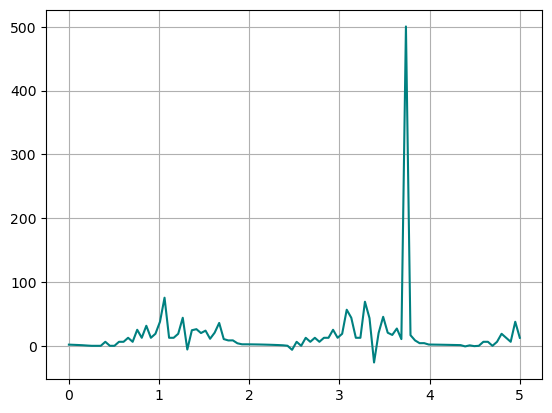

In [17]:
theta_2, theta_3 = [], []

for i in range(len(t_)):
    theta_2.append(posicion(t_[i], theta_1[i])[1])
    theta_3.append(posicion(t_[i], theta_1[i])[2])

plt.plot(t_, theta_3, color = 'teal')
plt.grid(True)

theta_3

### Cinetica

In [18]:
theta1, theta2, theta3 = dynamicsymbols('theta1, theta2, theta3')
OP, PQ, PS, QR, ORy, ma, mb, mc, md = symbols('OP, PQ, PS, QR, OR_y, m_A, m_B, m_C, m_D')
foax, foay, fabx, faby, fbcx, fbcy, fcdx, fcdy, fod = symbols('foa_x, foa_y, fab_x, fab_y, fbc_x, fbc_y, fcd_x, fcd_y, f_od')
Min, Fin = symbols('M_in, F_in') # Para describir por completo el movimiento del sistema
Ia, Ib, Ic, Id = symbols('I_a, I_b, I_c, I_d')
t = symbols('t')

#Definir los marcos de referencia
N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = A.orientnew('B', 'Axis', (N.z, -theta2))
C = B.orientnew('C', 'Axis', (N.z, -theta3))

In [19]:
params = {OP:0.2, PQ:0.15, QR:0.6, PS:0.15, ma:2, mb:3, mc:2, md:1, Ia:(1/12)*2*0.2**2, Ib:(1/36)*3*0.15**2, Ic:(1/12)*2*0.6**2, Id:0}

#Describir la posicion de los centros de masa m*(a**2+b**2)/18
cm_a = OP/2*A.x 
cm_b = OP*A.x + (2*PQ/3*B.x + PS/3*B.y)
cm_c = OP*A.x + PQ*B.x + QR/2*C.x 
cm_d = OP*A.x + PQ*B.x + QR*C.x

#Definir los vectores de las fuerzas
Foa = foax*N.x + foay*N.y
Fab = fabx*N.x + faby*N.y
Fbc = fbcx*N.x + fbcy*N.y
Fcd = fcdx*N.x + fcdy*N.y
Fod = fod*N.y

#Ecuaciones Newton-Euler
Fa = Foa - Fab - ma*9.81*N.y - ma*cm_a.diff(t,N).diff(t,N) #Ecuaciones de x-y
Fb = Fab - Fbc - mb*9.81*N.y - mb*cm_b.diff(t,N).diff(t,N)
Fc = Fbc - Fcd - mc*9.81*N.y - mc*cm_c.diff(t,N).diff(t,N)
Fd = Fin*N.x + Fcd + Fod - md*9.81*N.y - md*x.diff(t,t)*N.x

Ma = Min*N.z - OP/2*A.x.cross(Foa) + OP/2*A.x.cross(-Fab) - Ia*theta1.diff(t,t)*N.z
Mb = -(PQ/3*B.x + PS/3*B.y).cross(Fab) + (PQ/3*B.x + PS/3*B.y).cross(-Fbc) - Ib*(theta1+theta2).diff(t,t)*N.z
Mc = -QR/2*C.x.cross(Fbc) + QR/2*C.x.cross(-Fcd) - Ic*(theta1+theta2+theta3).diff(t,t)*N.z

#Sacar la lista de las ecuaciones 
eqList = []
for eq in [Fa, Fb, Fc, Fd]:
    eqList.append(eq.subs(params).simplify().dot(N.x))
    eqList.append(eq.subs(params).simplify().dot(N.y))

for eq in [Ma, Mb, Mc]:
    eqList.append(eq.subs(params).simplify().dot(N.z))

cinemat = [foax, foay, fabx, faby, fbcx, fbcy, fcdx, fcdy, fod, Min, Fin]

[A, b] = sp.linear_eq_to_matrix(eqList, cinemat)
A_fun = sp.lambdify(pos_var + vel_var + ace_var, A)
b_fun = sp.lambdify(pos_var + vel_var + ace_var, b)

In [20]:
b

Matrix([
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [21]:
t_ = np.linspace(0, 0.145, 100)
theta_1 = np.linspace(50, 75, 100)

thetadot_2 = []

for i in range(len(t_)):
    thetadot_2.append(cinematica(t_[i],theta_1[i], 3, 0)[5])

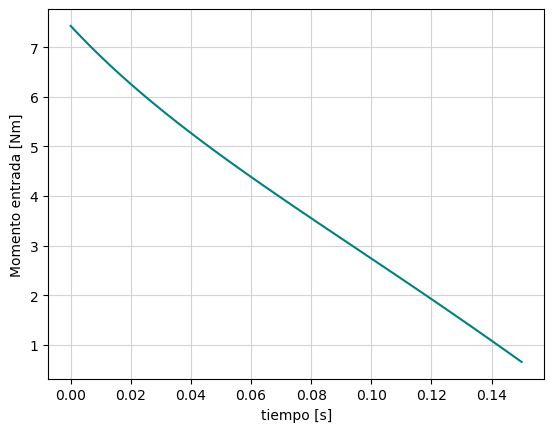

In [22]:
def inv_dinam(time, theta1, theta1dot, theta1ddot):
    args = cinematica(time, theta1, theta1dot, theta1ddot)
    outF = np.matmul(np.linalg.pinv(A_fun(*args)), b_fun(*args)).flatten()
    return outF

t_ = np.linspace(0, 0.15, 100) #0.145
theta_1 = np.linspace(50, 75, 100)

M_list = []

for i in range(len(t_)):
    M_list.append(inv_dinam(t_[i], theta_1[i], 3, 0)[9])

plt.plot(t_, M_list, color = 'teal')
plt.ylabel('Momento entrada [Nm]')
plt.xlabel('tiempo [s]')
plt.grid(True, color='lightgrey')